<a href="https://colab.research.google.com/github/nisanailapr123-debug/pm-turi4-clustering/blob/main/PM_P9_Nisa_Naila_2488010024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1 — Menyiapkan data & scaling (wajib).

In [ ]:
import pandas as pd

data = {
    'usia': [20, 25, 30, 35, 40, 22, 28, 45, 50, 33,
             24, 38, 42, 27, 31],
    'pendapatan': [30000, 40000, 50000, 60000, 80000, 30000, 50000, 90000, 10000, 60000,
                   40000, 70000, 80000, 50000, 60000],
    'skor_belanja': [80, 75, 60, 40, 20, 85, 65, 15, 10, 45,
                     78, 30, 25, 70, 55]
}

df = pd.DataFrame(data)

print(df)

    usia  pendapatan  skor_belanja
0     20       30000            80
1     25       40000            75
2     30       50000            60
3     35       60000            40
4     40       80000            20
5     22       30000            85
6     28       50000            65
7     45       90000            15
8     50       10000            10
9     33       60000            45
10    24       40000            78
11    38       70000            30
12    42       80000            25
13    27       50000            70
14    31       60000            55


In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)



Langkah 2 — Metode Elbow menentukan K.

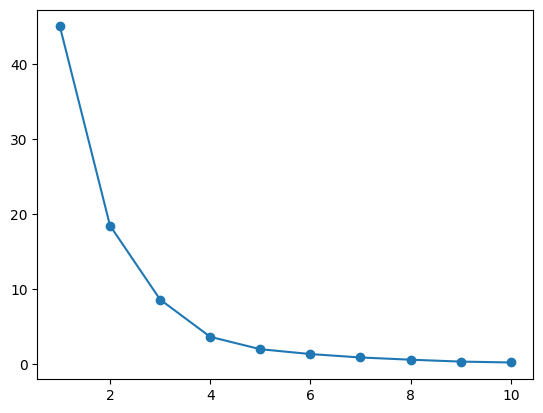

In [ ]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


Langkah 3 — Menjalankan K-Means (K=3).

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
0    8
1    6
2    1
Name: count, dtype: int64


Langkah 4 — Evaluasi silhouette score.

In [ ]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))


0.5278369322773673


Langkah 5 — Interpretasi: profil rata-rata tiap cluster.

In [ ]:
profil = df.groupby('cluster')[['usia','pendapatan',
        'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil


         usia  pendapatan  skor_belanja
cluster                                
0        25.9     43750.0          71.0
1        38.8     73333.3          29.2
2        50.0     10000.0          10.0


D. Latihan Mandiri

6.	Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.


In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
0    4
2    4
1    3
4    3
3    1
Name: count, dtype: int64


7.	Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Memilih fitur tanpa scaling
X = df[['usia', 'pendapatan', 'skor_belanja']]

# K-Means K=3 tanpa scaling
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster = kmeans.fit_predict(X)

# Menghitung silhouette score
score = silhouette_score(X, cluster)

print("Silhouette Score tanpa scaling:", round(score, 4))
print("Silhouette Score dengan scaling:", 0.5278)

Silhouette Score tanpa scaling: 0.5582
Silhouette Score dengan scaling: 0.5278


8.	Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).


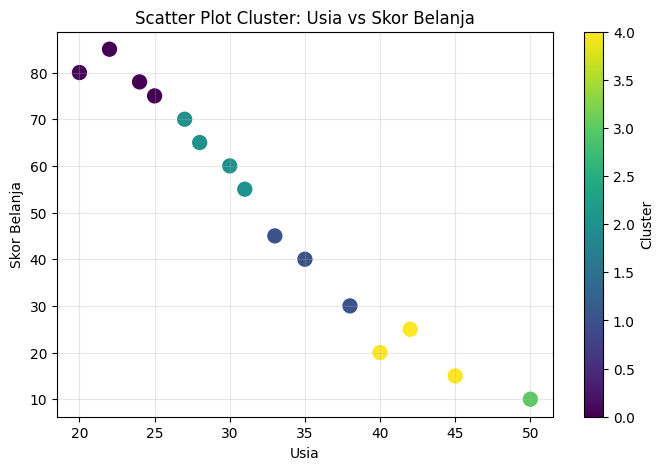

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df['usia'],
    df['skor_belanja'],
    c=df['cluster'],
    cmap='viridis',
    s=100
)

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Cluster: Usia vs Skor Belanja')
plt.colorbar(label='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

**Refleksi**

9.	Bagaimana K-Means menemukan kelompok tanpa label?

K-Means menemukan kelompok dengan mengelompokkan data berdasarkan kemiripan karakteristik dan jarak antar data. Algoritma ini menentukan pusat kelompok (centroid), memasukkan setiap data ke kelompok dengan centroid terdekat, lalu memperbarui posisi centroid berdasarkan rata-rata anggota kelompok. Proses ini diulang sampai posisi kelompok stabil. Karena tidak memerlukan label atau kategori yang ditentukan sebelumnya, K-Means termasuk metode unsupervised learning (pembelajaran tanpa label).


10.	Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

Metode Elbow menunjukkan siku di K=3 karena penambahan jumlah cluster hingga tiga memberikan penurunan nilai inertia yang cukup besar, sedangkan penambahan cluster setelahnya cenderung memberikan penurunan yang lebih kecil. Inertia mengukur jumlah kuadrat jarak data terhadap centroid cluster masing-masing. Oleh karena itu, K=3 dipilih sebagai perkiraan jumlah cluster yang cukup baik karena dapat mengelompokkan data tanpa menambah jumlah kelompok secara berlebihan.

Catatan: siku di K=3 merupakan interpretasi grafik Elbow. Bentuk grafik yang kamu peroleh menjadi dasar untuk memastikan pemilihan tersebut.


11.	Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

Scaling penting karena K-Means menggunakan jarak untuk mengelompokkan data. Pada dataset ini, fitur pendapatan memiliki rentang angka yang jauh lebih besar daripada usia dan skor belanja. Tanpa scaling, pendapatan dapat lebih mendominasi perhitungan jarak sehingga pembentukan cluster lebih banyak dipengaruhi oleh fitur tersebut. Dengan scaling, skala setiap fitur disamakan sehingga kontribusinya dalam perhitungan jarak menjadi lebih seimbang. Jika scaling dilewatkan, hasil pengelompokan dapat berbeda dan kurang mewakili kemiripan berdasarkan seluruh fitur yang digunakan.